In [1]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

In [2]:
data = {
    'Price': [299, 499, 799, 999, 1499],
    'Rating': [3.5, 4.0, 4.2, 4.5, 4.9],
    'Sales': [120, 250, 180, 400, 550]
}

df = pd.DataFrame(data)

In [3]:
X = df[['Price','Rating']]
y = df[['Sales']]

In [4]:
from sklearn.model_selection import train_test_split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [8]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
X_trained_scaled = pd.DataFrame(
    X_train_scaled, columns=X_train.columns, index=X_train.index
)
X_tested_scaled = pd.DataFrame(
    X_test_scaled, columns=X_test.columns, index=X_test.index
)

In [12]:
print(f'Trained Data:{X_trained_scaled}')
print(f'Tested Data:{X_tested_scaled}')

Trained Data:      Price    Rating
4  1.000000  1.000000
2  0.416667  0.500000
0  0.000000  0.000000
3  0.583333  0.714286
Tested Data:      Price    Rating
1  0.166667  0.357143


In [13]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

data = {
    'Price': [299, 399, 499, 599, 699, 799, 999, 9999],
    'Monthly_Sales': [150, 200, 180, 250, 300, 280, 350, 20]
}

df = pd.DataFrame(data)
print(df)

   Price  Monthly_Sales
0    299            150
1    399            200
2    499            180
3    599            250
4    699            300
5    799            280
6    999            350
7   9999             20


In [15]:
std_scaler = StandardScaler()
df_scaled = std_scaler.fit_transform(df)
print(df_scaled)

[[-0.47813534 -0.68611648]
 [-0.44599179 -0.16829272]
 [-0.41384823 -0.37542222]
 [-0.38170468  0.34953104]
 [-0.34956113  0.8673548 ]
 [-0.31741758  0.66022529]
 [-0.25313047  1.38517855]
 [ 2.63978923 -2.03245825]]


In [17]:
df_standard = pd.DataFrame(
    df_scaled,
    columns=df.columns,
    index=df.index
)
print(df_standard)

      Price  Monthly_Sales
0 -0.478135      -0.686116
1 -0.445992      -0.168293
2 -0.413848      -0.375422
3 -0.381705       0.349531
4 -0.349561       0.867355
5 -0.317418       0.660225
6 -0.253130       1.385179
7  2.639789      -2.032458


In [23]:
X = df[['Price']]
y = df[['Monthly_Sales']]

In [24]:
from sklearn.model_selection import train_test_split

In [28]:
minmax_scaler = MinMaxScaler()

df_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)

print(df_minmax)

      Price  Monthly_Sales
0  0.000000       0.393939
1  0.010309       0.545455
2  0.020619       0.484848
3  0.030928       0.696970
4  0.041237       0.848485
5  0.051546       0.787879
6  0.072165       1.000000
7  1.000000       0.000000


In [30]:
comparison = pd.DataFrame({
    'Original_Price': df['Price'],
    'StandardScaler': df_standard['Price'],
    'MinMaxScaler': df_minmax['Price']
})
print(comparison)

   Original_Price  StandardScaler  MinMaxScaler
0             299       -0.478135      0.000000
1             399       -0.445992      0.010309
2             499       -0.413848      0.020619
3             599       -0.381705      0.030928
4             699       -0.349561      0.041237
5             799       -0.317418      0.051546
6             999       -0.253130      0.072165
7            9999        2.639789      1.000000


In [31]:
import matplotlib.pyplot as plt

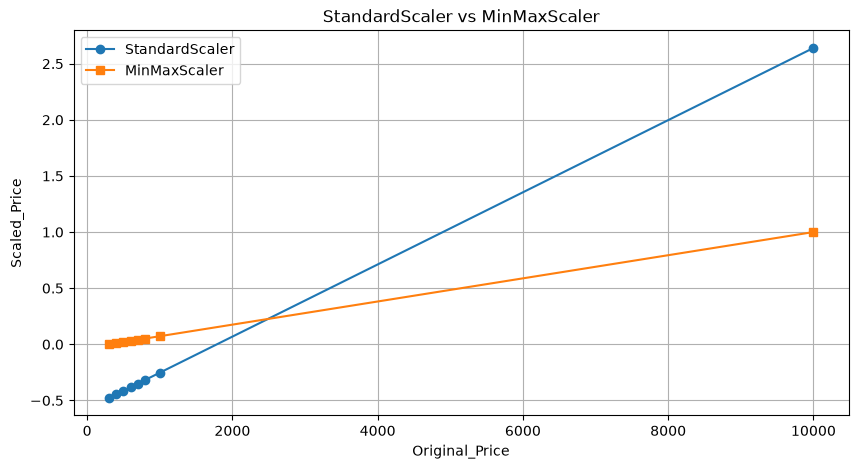

In [34]:
plt.figure(figsize=(10,5))
plt.plot(df['Price'], df_standard['Price'],
         marker='o', label='StandardScaler'
        )
plt.plot(df['Price'], df_minmax['Price'],
         marker='s', label='MinMaxScaler'
        )
plt.xlabel('Original_Price')
plt.ylabel('Scaled_Price')
plt.title('StandardScaler vs MinMaxScaler')
plt.legend()
plt.grid(True)
plt.show()

In [35]:
df_without_outlier = df[df['Price'] < 5000].copy()

standard_without = StandardScaler()
minmax_without = MinMaxScaler()

standard_result = standard_without.fit_transform(
    df_without_outlier[['Price']]
)

minmax_result = minmax_without.fit_transform(
    df_without_outlier[['Price']]
)

In [36]:
comparison_without_outlier = pd.DataFrame({
    'Original': df_without_outlier['Price'].values,
    'StandardScaler': standard_result[:, 0],
    'MinMaxScaler': minmax_result[:, 0]
})

print(comparison_without_outlier)

   Original  StandardScaler  MinMaxScaler
0       299       -1.408406      0.000000
1       399       -0.960277      0.142857
2       499       -0.512148      0.285714
3       599       -0.064018      0.428571
4       699        0.384111      0.571429
5       799        0.832240      0.714286
6       999        1.728498      1.000000
